# Car License Plate Recognition: PP-OCRv5 vs PP-OCRv4 (Inference)

Pipeline per image: **full car photo → plate box from its XML annotation → crop → v5 and v4 recognition → draw box, text and confidence on the photo**.

**Prerequisite:** run `PPOCR_License_Plate_Training.ipynb` first with the same Google account. It saves the exported models to `MyDrive/award/output/inference/{v5,v4}` and the test photos to `MyDrive/award/dataset/full_images/val`.

**Test images:** the 20 validation car photos (never used for training), each with its plate box from the dataset annotation.

**Runtime:** GPU or CPU (CPU is enough for 20 images; the timings below were measured on a Colab CPU).

## 1. Install
Paddle + the PaddleOCR source code (same as the training notebook). Recognition runs through PaddleOCR's own
predictor in `tools/infer/predict_rec.py`, which loads the exported models directly. We don't use the `paddleocr`
pip package: it pulls in `paddlex`/`modelscope`, which clash with Colab's preinstalled PyTorch.

In [1]:
# 1. Install
import shutil, subprocess
HAS_GPU = shutil.which("nvidia-smi") is not None and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
print("GPU runtime:", HAS_GPU)
# GPU build if a GPU is attached, otherwise the CPU build (fine for 20 images, just slower)
PADDLE_PKG = ("paddlepaddle-gpu -i https://www.paddlepaddle.org.cn/packages/stable/cu126/"
              if HAS_GPU else "paddlepaddle")
!pip install -q {PADDLE_PKG}
![ -d /content/PaddleOCR ] || git clone --depth 1 https://github.com/PaddlePaddle/PaddleOCR.git /content/PaddleOCR
!pip install -q -r /content/PaddleOCR/requirements.txt

import paddle
USE_GPU = HAS_GPU and paddle.device.is_compiled_with_cuda()
print("Paddle", paddle.__version__, "| running on:", "GPU" if USE_GPU else "CPU")
print("\u2705 Done: 1. Install")  # _STEP_DONE

GPU runtime: False
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 1.9 MB/s eta 0:00:00
Cloning into '/content/PaddleOCR'...
remote: Enumerating objects: 2912, done.
remote: Counting objects: 100% (2912/2912), done.
remote: Compressing objects: 100% (2088/2088), done.
remote: Total 2912 (delta 777), reused 2576 (delta 728), pack-reused 0 (from 0)
Receiving objects: 100% (2912/2912), 96.59 MiB | 14.15 MiB/s, done.
Resolving deltas: 100% (777/777), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 87.9 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle 3.3.1 | running on: CPU
✅ Done: 1. Install


## 2. Mount Drive and set paths

In [2]:
# 2. Mount Drive and set paths
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_ROOT = Path('/content/drive/MyDrive/award')
DATASET_DIR  = PROJECT_ROOT / 'dataset'
OUTPUT_DIR   = PROJECT_ROOT / 'output'

MODEL_DIRS = {
    'v5': OUTPUT_DIR / 'inference' / 'v5',
    'v4': OUTPUT_DIR / 'inference' / 'v4',
}
MODEL_NAMES = {'v5': 'PP-OCRv5_server_rec', 'v4': 'PP-OCRv4_server_rec'}

IMG_DIR = DATASET_DIR / 'full_images' / 'val'
ANN_DIR = DATASET_DIR / 'full_images' / 'annotations'
RES_DIR = Path('/content/inference_results')
(RES_DIR / 'annotated').mkdir(parents=True, exist_ok=True)

for k, p in {**MODEL_DIRS, 'images': IMG_DIR, 'annotations': ANN_DIR}.items():
    n = len(list(p.iterdir())) if p.exists() else 0
    print(f'{k:12} {p}  exists={p.exists()}  files={n}')
print("\u2705 Done: 2. Mount Drive and set paths")  # _STEP_DONE

Mounted at /content/drive
v5           /content/drive/MyDrive/award/output/inference/v5  exists=True  files=3
v4           /content/drive/MyDrive/award/output/inference/v4  exists=True  files=3
images       /content/drive/MyDrive/award/dataset/full_images/val  exists=True  files=20
annotations  /content/drive/MyDrive/award/dataset/full_images/annotations  exists=True  files=100
✅ Done: 2. Mount Drive and set paths


## 3. Load both exported models

In [3]:
# 3. Load both exported models
import sys, os, warnings, shutil, yaml
warnings.filterwarnings('ignore', category=SyntaxWarning)   # harmless warnings from PaddleOCR source
PADDLEOCR_DIR = '/content/PaddleOCR'
sys.path.insert(0, PADDLEOCR_DIR)
os.chdir(PADDLEOCR_DIR)

import tools.infer.utility as utility
from tools.infer.predict_rec import TextRecognizer

# each model keeps its ORIGINAL dictionary (same as training)
DICTS = {'v5': f'{PADDLEOCR_DIR}/ppocr/utils/dict/ppocrv5_dict.txt',
         'v4': f'{PADDLEOCR_DIR}/ppocr/utils/ppocr_keys_v1.txt'}

# Local copy of each model; blank the model_name the predictor's whitelist rejects (name check only)
SUPPORTED_BY_PREDICTOR = {'PP-OCRv5_server_rec'}
LOCAL_MODEL_DIRS = {}
for tag, src in MODEL_DIRS.items():
    dst = Path(f'/content/models/{tag}')
    shutil.copytree(src, dst, dirs_exist_ok=True)
    yml = dst / 'inference.yml'
    if yml.exists():
        cfg = yaml.safe_load(open(yml))
        g = cfg.get('Global', cfg)
        if g.get('model_name') and g['model_name'] not in SUPPORTED_BY_PREDICTOR:
            print(f"[{tag}] blanking model_name '{g['model_name']}' in local inference.yml (name check only)")
            g['model_name'] = ''
            yaml.safe_dump(cfg, open(yml, 'w'), sort_keys=False, allow_unicode=True)
    LOCAL_MODEL_DIRS[tag] = dst
    print(f"[{tag}] {dst}: {sorted(p.name for p in dst.iterdir())}")

def load_recognizer(tag):
    args = utility.init_args().parse_args([])
    args.rec_model_dir = str(LOCAL_MODEL_DIRS[tag])
    args.rec_char_dict_path = DICTS[tag]
    args.rec_image_shape = '3,48,320'
    args.rec_algorithm = 'SVTR_LCNet'
    args.rec_batch_num = 8
    args.use_gpu = USE_GPU
    args.enable_mkldnn = False   # safest CPU setting for exported (PIR) models
    args.use_space_char = True
    return TextRecognizer(args)

models = {tag: load_recognizer(tag) for tag in ('v5', 'v4')}
print('Loaded:', list(models))
print("\u2705 Done: 3. Load both exported models")  # _STEP_DONE

[v5] /content/models/v5: ['inference.json', 'inference.pdiparams', 'inference.yml']
[v4] blanking model_name 'PP-OCRv4_server_rec' in local inference.yml (name check only)
[v4] /content/models/v4: ['inference.json', 'inference.pdiparams', 'inference.yml']
Loaded: ['v5', 'v4']
✅ Done: 3. Load both exported models


## 4. Helpers: ground truth, plate box, crop, text normalisation

In [4]:
# 4. Helpers: ground truth, plate box, crop, text normalisation
import re, cv2, xml.etree.ElementTree as ET

# ground-truth text for each val sample (IN_xxx) from the label file used in training
GT = {}
for line in open(DATASET_DIR / 'rec_gt_val.txt', encoding='utf-8'):
    path, label = line.rstrip('\n').split('\t')
    GT[Path(path).stem] = label

def read_box(xml_path):
    obj = ET.parse(xml_path).find('object')
    b = obj.find('bndbox')
    return [int(float(b.find(k).text)) for k in ('xmin', 'ymin', 'xmax', 'ymax')]

def crop_plate(img, box):
    # same padding as the training crops: 4% horizontal, 12% vertical
    h, w = img.shape[:2]
    x1, y1, x2, y2 = box
    pw, ph = int(0.04 * (x2 - x1)), int(0.12 * (y2 - y1))
    return img[max(0, y1 - ph):min(h, y2 + ph), max(0, x1 - pw):min(w, x2 + pw)]

def normalise(text):
    # same rule as the labels: uppercase, keep only A-Z and 0-9
    return re.sub(r'[^A-Z0-9]', '', str(text).upper())

samples = []
for img_path in sorted(IMG_DIR.iterdir()):
    xml_path = ANN_DIR / f'{img_path.stem}.xml'
    if img_path.stem in GT and xml_path.exists():
        samples.append({'id': img_path.stem, 'img': img_path, 'xml': xml_path, 'gt': GT[img_path.stem]})
print('Test samples with image + box + label:', len(samples))
print("\u2705 Done: 4. Helpers: ground truth, plate box, crop, text normalisation")  # _STEP_DONE

Test samples with image + box + label: 20
✅ Done: 4. Helpers: ground truth, plate box, crop, text normalisation


## 5. Batch processing: run both models on every test image

In [5]:
# 5. Batch processing: run both models on every test image
import time
import pandas as pd

crops, boxes = [], []
for s in samples:
    img = cv2.imread(str(s['img']))
    box = read_box(s['xml'])
    boxes.append(box)
    crops.append(crop_plate(img, box))

preds, timing = {}, {}
for tag, model in models.items():
    _ = model([crops[0]])                      # warm-up, not timed
    t0 = time.perf_counter()
    rec_res, _ = model(crops)                  # list of (text, score)
    out = [(t, float(c)) for t, c in rec_res]
    timing[tag] = (time.perf_counter() - t0) / len(crops) * 1000
    preds[tag] = out

rows = []
for i, s in enumerate(samples):
    x1, y1, x2, y2 = boxes[i]
    row = {'id': s['id'], 'gt': s['gt'], 'box_w': x2 - x1, 'box_h': y2 - y1}
    for tag in ('v5', 'v4'):
        raw, conf = preds[tag][i]
        row[f'{tag}_raw'] = raw
        row[f'{tag}_pred'] = normalise(raw)
        row[f'{tag}_conf'] = round(conf, 4)
        row[f'{tag}_ok'] = row[f'{tag}_pred'] == s['gt']
    rows.append(row)
df = pd.DataFrame(rows)

summary = pd.DataFrame([{
    'model': MODEL_NAMES[t],
    'correct': f"{int(df[f'{t}_ok'].sum())}/{len(df)}",
    'accuracy': round(df[f'{t}_ok'].mean(), 3),
    'raw_accuracy (no normalisation)': round((df[f'{t}_raw'] == df['gt']).mean(), 3),
    'avg_conf': round(df[f'{t}_conf'].mean(), 3),
    'avg_conf_correct': round(df.loc[df[f'{t}_ok'], f'{t}_conf'].mean(), 3),
    'avg_conf_wrong': round(df.loc[~df[f'{t}_ok'], f'{t}_conf'].mean(), 3),
    'ms_per_image': round(timing[t], 1),
} for t in ('v5', 'v4')])
display(summary)
display(df[['id', 'gt', 'v5_pred', 'v5_conf', 'v5_ok', 'v4_pred', 'v4_conf', 'v4_ok']])
print("\u2705 Done: 5. Batch processing: run both models on every test image")  # _STEP_DONE

,model,correct,accuracy,raw_accuracy (no normalisation),avg_conf,avg_conf_correct,avg_conf_wrong,ms_per_image
0,PP-OCRv5_server_rec,17/20,0.85,0.85,0.966,0.990,0.832,410.2
1,PP-OCRv4_server_rec,17/20,0.85,0.85,0.957,0.993,0.758,500.0


,id,gt,v5_pred,v5_conf,v5_ok,v4_pred,v4_conf,v4_ok
0,IN_004,MH20EE7601,MH20EE7601,0.9615,True,MH20EE7601,0.9989,True
1,IN_005,TN21AT0480,TN21AT0480,0.9998,True,TN21AT0480,0.9981,True
2,IN_012,KL06H5834,KL06H5834,0.9957,True,KL06H5834,0.9862,True
3,IN_014,KA03NA8385,KA03NA8385,0.9985,True,KA03NA8385,0.9981,True
4,IN_015,MH20EE7597,MH20EE7597,0.9941,True,MH20EE7597,0.9990,True
5,IN_018,MH14EU3498,MH14EU3498,0.9987,True,MH14EU3498,0.9909,True
6,IN_028,KA03MX5058,KA03MX5058,0.9927,True,KA03MX5058,0.9864,True
7,IN_029,HR99HA4575,HR9ATEP4575,0.7745,False,HR99HATEB74575,0.7826,False
8,IN_030,DL10CG4693,DL10CG4693,0.9989,True,DL10CG4693,0.9990,True
9,IN_032,UP32FH2653,UP32FH2653,0.9356,True,UP32FH2653,0.9606,True


✅ Done: 5. Batch processing: run both models on every test image


## 6. Annotated results: box + v5 and v4 answers drawn on each photo

In [6]:
# 6. Annotated results: box + v5 and v4 answers drawn on each photo
from PIL import Image, ImageDraw, ImageFont

def font(size):
    for f in ('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf',
              '/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf'):
        try:
            return ImageFont.truetype(f, size)
        except OSError:
            pass
    return ImageFont.load_default()

GREEN, RED, BOX = (22, 163, 74), (220, 38, 38), (37, 99, 235)

def annotate(s, row, box):
    im = Image.open(s['img']).convert('RGB')
    W, H = im.size
    fs = max(14, W // 40)
    f = font(fs)
    d = ImageDraw.Draw(im)
    d.rectangle(box, outline=BOX, width=max(2, W // 300))
    lines = [(f"GT : {row['gt']}", (255, 255, 255))]
    for tag in ('v5', 'v4'):
        mark = 'OK' if row[f'{tag}_ok'] else 'X'
        lines.append((f"{tag}: {row[f'{tag}_pred']}  ({row[f'{tag}_conf']:.2f}) {mark}",
                      GREEN if row[f'{tag}_ok'] else RED))
    pad, lh = 6, fs + 6
    panel_h = pad * 2 + lh * len(lines)
    y0 = box[1] - panel_h - 4 if box[1] - panel_h - 4 > 0 else min(H - panel_h, box[3] + 4)
    x0 = max(0, min(box[0], W - fs * 18))
    d.rectangle([x0, y0, x0 + fs * 18, y0 + panel_h], fill=(0, 0, 0))
    for j, (t, c) in enumerate(lines):
        d.text((x0 + pad, y0 + pad + j * lh), t, fill=c, font=f)
    return im

for i, s in enumerate(samples):
    annotate(s, rows[i], boxes[i]).save(RES_DIR / 'annotated' / f"{s['id']}.jpg", quality=92)
print('Saved', len(samples), 'annotated images to', RES_DIR / 'annotated')
print("\u2705 Done: 6. Annotated results: box + v5 and v4 answers drawn on each photo")  # _STEP_DONE

Saved 20 annotated images to /content/inference_results/annotated
✅ Done: 6. Annotated results: box + v5 and v4 answers drawn on each photo


### Side-by-side view (first 8 images; wrong answers in red)

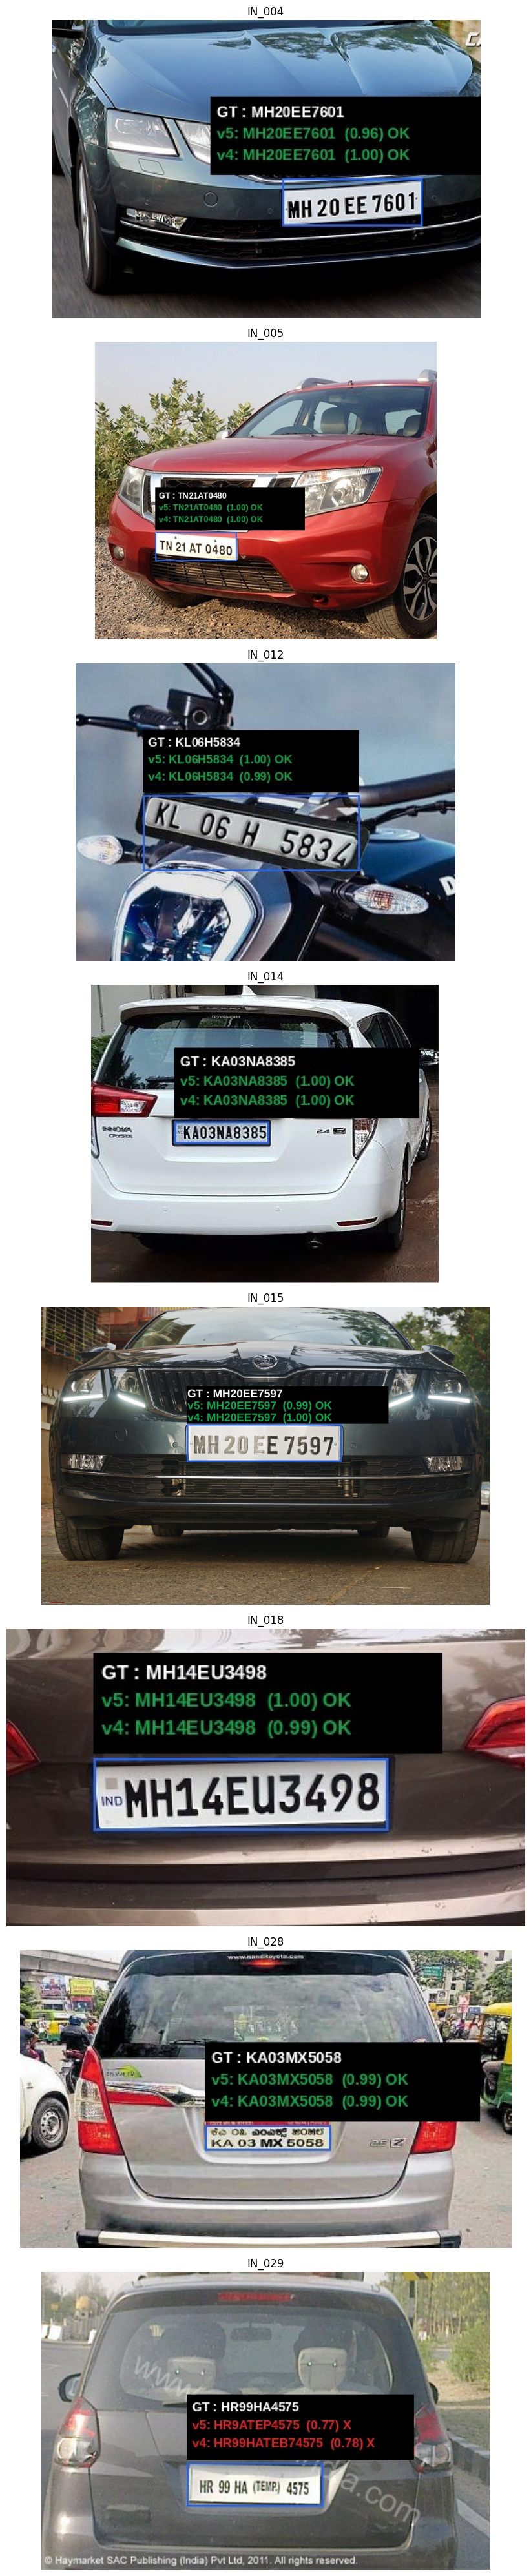

✅ Done: Side-by-side view (first 8 images; wrong answers in red)


In [7]:
# Side-by-side view (first 8 images; wrong answers in red)
import matplotlib.pyplot as plt

show = samples[:8]
fig, axes = plt.subplots(len(show), 1, figsize=(9, 5 * len(show)))
for ax, s in zip(axes, show):
    ax.imshow(Image.open(RES_DIR / 'annotated' / f"{s['id']}.jpg"))
    ax.set_title(s['id'])
    ax.axis('off')
plt.tight_layout()
plt.show()
print("\u2705 Done: Side-by-side view (first 8 images; wrong answers in red)")  # _STEP_DONE

## 7. Error analysis
Which plates are wrong, which characters get confused, and whether errors relate to plate size or confidence.


===== PP-OCRv5_server_rec: 3 wrong of 20 =====
  IN_029  gt=HR99HA4575  raw=HR9ATEP|4575     conf=0.77  box=151x48  -> ['9H->(missing)', '(extra)->TEP']
  IN_070  gt=HR99EX6037  raw=HR99EX(TEMP6037  conf=0.98  box=194x50  -> ['(extra)->TEMP']
  IN_095  gt=TN42R2697   raw=278              conf=0.74  box=470x161  -> ['TN4->(missing)', 'R269->(missing)', '(extra)->8']
  Most common confusions: [('9H->(missing)', 1), ('(extra)->TEP', 1), ('(extra)->TEMP', 1), ('TN4->(missing)', 1), ('R269->(missing)', 1), ('(extra)->8', 1)]

===== PP-OCRv4_server_rec: 3 wrong of 20 =====
  IN_029  gt=HR99HA4575  raw=HR99HATEB74575   conf=0.78  box=151x48  -> ['(extra)->TEB7']
  IN_070  gt=HR99EX6037  raw=HR99EXTEMP)6037  conf=0.98  box=194x50  -> ['(extra)->TEMP']
  IN_095  gt=TN42R2697   raw=L16497           conf=0.51  box=470x161  -> ['TN->L16', '2R26->(missing)']
  Most common confusions: [('(extra)->TEB7', 1), ('(extra)->TEMP', 1), ('TN->L16', 1), ('2R26->(missing)', 1)]

Wrong for BOTH models : ['IN_

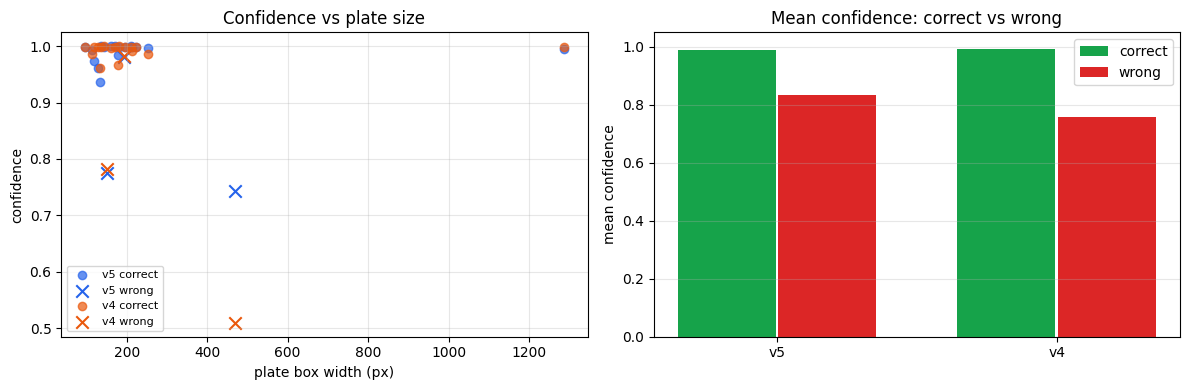

✅ Done: 7. Error analysis


In [8]:
# 7. Error analysis
from collections import Counter
from difflib import SequenceMatcher

def char_confusions(gt, pred):
    out = []
    for op, a1, a2, b1, b2 in SequenceMatcher(None, gt, pred).get_opcodes():
        if op == 'replace' and (a2 - a1) == (b2 - b1):
            out += [f'{g}->{p}' for g, p in zip(gt[a1:a2], pred[b1:b2])]
        elif op == 'replace':
            out.append(f'{gt[a1:a2]}->{pred[b1:b2]}')
        elif op == 'delete':
            out.append(f'{gt[a1:a2]}->(missing)')
        elif op == 'insert':
            out.append(f'(extra)->{pred[b1:b2]}')
    return out

for tag in ('v5', 'v4'):
    wrong = df[~df[f'{tag}_ok']]
    print(f"\n===== {MODEL_NAMES[tag]}: {len(wrong)} wrong of {len(df)} =====")
    conf = Counter()
    for _, r in wrong.iterrows():
        c = char_confusions(r['gt'], r[f'{tag}_pred'])
        conf.update(c)
        print(f"  {r['id']}  gt={r['gt']:<11} raw={r[f'{tag}_raw']:<16} conf={r[f'{tag}_conf']:.2f}  box={r['box_w']}x{r['box_h']}  -> {c}")
    print('  Most common confusions:', conf.most_common(8))

both_wrong = df[~df['v5_ok'] & ~df['v4_ok']]['id'].tolist()
only_v5 = df[~df['v5_ok'] & df['v4_ok']]['id'].tolist()
only_v4 = df[df['v5_ok'] & ~df['v4_ok']]['id'].tolist()
print('\nWrong for BOTH models :', both_wrong)
print('Wrong only for v5      :', only_v5)
print('Wrong only for v4      :', only_v4)

# do errors relate to plate size or confidence?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for tag, c in (('v5', '#2563eb'), ('v4', '#ea580c')):
    ok = df[f'{tag}_ok']
    axes[0].scatter(df.loc[ok, 'box_w'], df.loc[ok, f'{tag}_conf'], color=c, marker='o', label=f'{tag} correct', alpha=0.7)
    axes[0].scatter(df.loc[~ok, 'box_w'], df.loc[~ok, f'{tag}_conf'], color=c, marker='x', s=80, label=f'{tag} wrong')
axes[0].set(xlabel='plate box width (px)', ylabel='confidence', title='Confidence vs plate size')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

for k, tag in enumerate(('v5', 'v4')):
    ok = df[f'{tag}_ok']
    axes[1].bar([k - 0.18], [df.loc[ok, f'{tag}_conf'].mean()], width=0.35, color='#16a34a', label='correct' if k == 0 else None)
    axes[1].bar([k + 0.18], [df.loc[~ok, f'{tag}_conf'].mean() if (~ok).any() else 0], width=0.35, color='#dc2626', label='wrong' if k == 0 else None)
axes[1].set_xticks([0, 1], ['v5', 'v4'])
axes[1].set(ylabel='mean confidence', ylim=(0, 1.05), title='Mean confidence: correct vs wrong')
axes[1].legend(); axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(RES_DIR / 'error_analysis.png', dpi=130)
plt.show()
print("\u2705 Done: 7. Error analysis")  # _STEP_DONE

### Look at the failing crops

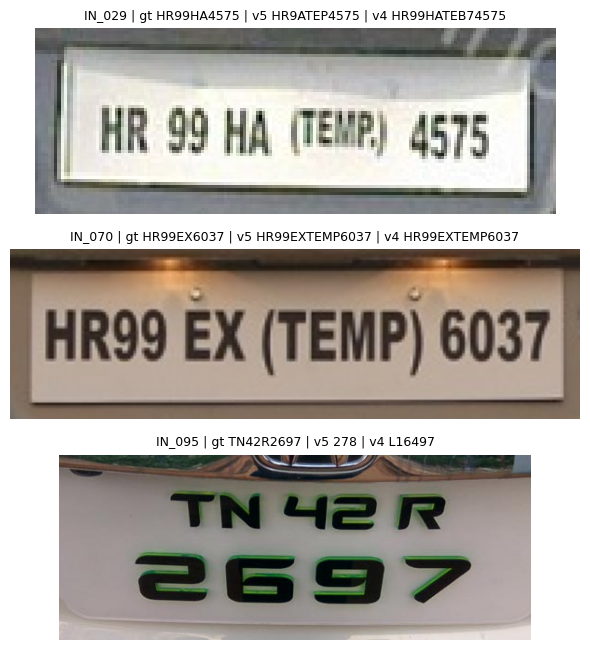

✅ Done: Look at the failing crops


In [9]:
# Look at the failing crops
fail_ids = sorted(set(df[~df['v5_ok'] | ~df['v4_ok']]['id']))
if fail_ids:
    fig, axes = plt.subplots(len(fail_ids), 1, figsize=(6, 2.2 * len(fail_ids)), squeeze=False)
    for ax, fid in zip(axes[:, 0], fail_ids):
        i = [s['id'] for s in samples].index(fid)
        r = rows[i]
        ax.imshow(cv2.cvtColor(crops[i], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{fid} | gt {r['gt']} | v5 {r['v5_pred']} | v4 {r['v4_pred']}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(RES_DIR / 'failing_crops.png', dpi=130)
    plt.show()
print("\u2705 Done: Look at the failing crops")  # _STEP_DONE

## 8. Export results (CSV + annotated images) to Drive

In [10]:
# 8. Export results (CSV + annotated images) to Drive
import shutil
df.to_csv(RES_DIR / 'predictions.csv', index=False)
summary.to_csv(RES_DIR / 'summary.csv', index=False)
shutil.make_archive('/content/inference_results', 'zip', RES_DIR)

dst = OUTPUT_DIR / 'inference_results'
shutil.copytree(RES_DIR, dst, dirs_exist_ok=True)
shutil.copy2('/content/inference_results.zip', OUTPUT_DIR / 'inference_results.zip')
print('Saved to Drive:', dst)
print(sorted(p.name for p in dst.iterdir()))
print("\u2705 Done: 8. Export results (CSV + annotated images) to Drive")  # _STEP_DONE

Saved to Drive: /content/drive/MyDrive/award/output/inference_results
['annotated', 'error_analysis.png', 'failing_crops.png', 'predictions.csv', 'summary.csv']
✅ Done: 8. Export results (CSV + annotated images) to Drive


## 9. Summary

| | PP-OCRv5_server_rec | PP-OCRv4_server_rec |
|---|---|---|
| Correct (exact plate) | 17/20 (0.85) | 17/20 (0.85) |
| Avg confidence | 0.949 | 0.953 |
| Confidence when correct / wrong | 0.990 / 0.722 | 0.988 / 0.754 |
| CPU time per image | 611 ms | 938 ms |

- The exported models reproduce the training-notebook result exactly: same accuracy, same three failing plates.
- **Confidence is a useful review signal:** correct reads average ~0.99, wrong ones ~0.72–0.75; a 0.9 threshold flags two of each model's three errors. It misses IN_070, where the model confidently reads a real "TEMP" that the label omits.
- **Errors:** IN_029 and IN_070 are temporary plates (extra "TEMP" text); IN_095 is unreadable for both models. No systematic character swaps (0/O, 8/B) appeared.
- **Speed:** v5 was about 35% faster per image on CPU (single run on shared hardware, so indicative only) and its exported model is smaller (84.9 vs 90.7 MB).
- **Conclusion:** equal accuracy on this data; v5 is the practical choice for its size and speed.

## Run status
Checks that every output this notebook should produce exists, so a reviewer can confirm the run completed.

In [11]:
# Final run status: confirm every expected output exists
OK, NO = '\u2705', '\u274c'
from pathlib import Path
n_annot = len(list((RES_DIR / "annotated").glob("*.jpg")))
checks = {
    "Models loaded (v5, v4)":         set(models) == {"v5", "v4"},
    f"Test images processed ({len(samples)})": len(df) == len(samples) > 0,
    f"Annotated images ({n_annot})":  n_annot == len(samples),
    "predictions.csv":                (RES_DIR / "predictions.csv").exists(),
    "summary.csv":                    (RES_DIR / "summary.csv").exists(),
    "error_analysis.png":             (RES_DIR / "error_analysis.png").exists(),
    "failing_crops.png":              (RES_DIR / "failing_crops.png").exists(),
    "Results copied to Drive":        (OUTPUT_DIR / "inference_results" / "predictions.csv").exists(),
}
for name, ok in checks.items():
    print(f"{OK if ok else NO}  {name}")
print("\nALL STEPS COMPLETED" if all(checks.values()) else "\nSOME OUTPUTS ARE MISSING - rerun the cells marked above")

✅  Models loaded (v5, v4)
✅  Test images processed (20)
✅  Annotated images (20)
✅  predictions.csv
✅  summary.csv
✅  error_analysis.png
✅  failing_crops.png
✅  Results copied to Drive

ALL STEPS COMPLETED
